# Tema 3.1 (II) · Características profundas: CNN y CLIP

**Algoritmos y Arquitecturas para Procesado de Imágenes** · Grado en Ciencia de Datos e IA

En el notebook anterior *diseñamos* los descriptores a mano. Aquí dejamos que una red neuronal los **aprenda**. Veremos:

1. Qué hace una capa convolucional (convolución y *pooling* a mano, sin redes).
2. Una CNN preentrenada como **extractor de características** (*transfer learning*).
3. Comparar píxeles crudos, HOG y embeddings de CNN con el mismo clasificador.
4. Visualizar el espacio de características con t-SNE.
5. **CLIP**: imágenes y texto en el mismo espacio; búsqueda por texto.

**Datos:** un subconjunto de CIFAR-10 (60 000 imágenes 32×32 de 10 clases), que `torchvision` descarga solo (~170 MB).

> **Antes de empezar en Colab:** *Entorno de ejecución → Cambiar tipo de entorno → GPU T4*. Funciona también sin GPU, pero la extracción de embeddings tarda unos minutos más. Las celdas marcadas con **[Colab]** necesitan PyTorch.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from skimage import data, color, transform, feature, util

plt.rcParams['figure.dpi'] = 100

## 1. ¿Qué hace una capa convolucional?

Una capa convolucional desliza pequeños filtros (kernels) sobre la imagen; cada filtro produce un **mapa de características**. Las primeras capas de una CNN entrenada aprenden filtros muy parecidos a detectores de bordes como estos, que aquí escribimos a mano. Después, el *max pooling* reduce la resolución quedándose con la respuesta máxima de cada bloque.

¿Coincide con scipy.signal.correlate2d? True


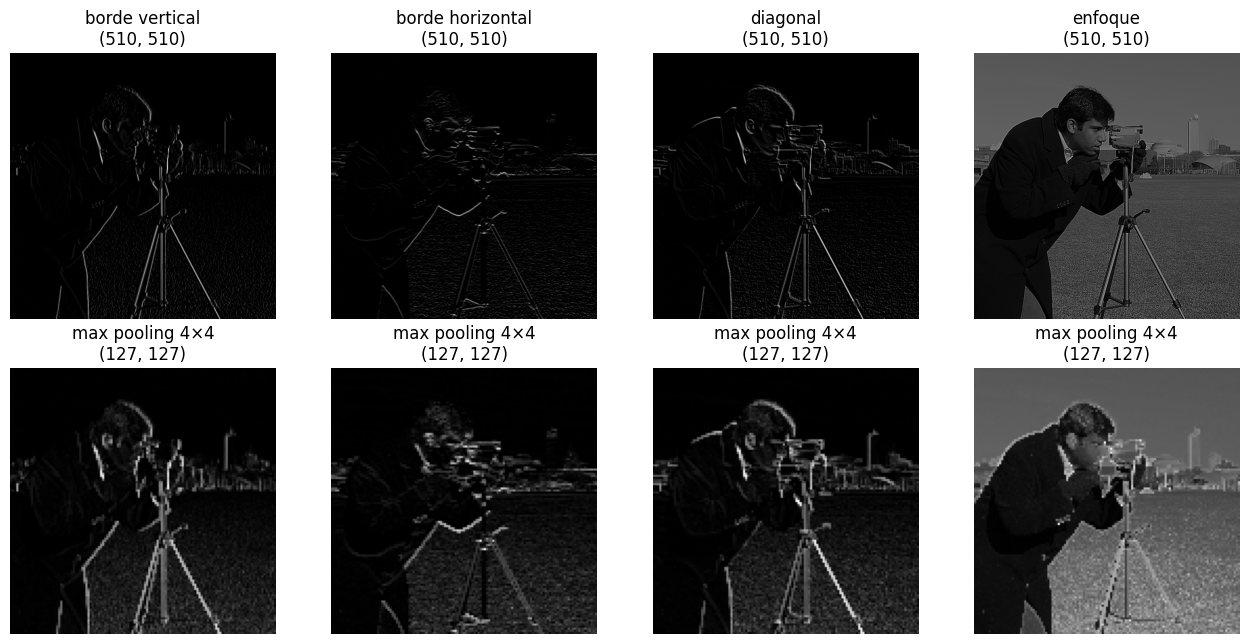

In [2]:
img = util.img_as_float(data.camera())

kernels = {
    'borde vertical': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    'borde horizontal': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    'diagonal': np.array([[0, 1, 2], [-1, 0, 1], [-2, -1, 0]], float),
    'enfoque': np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}

def conv2d(x, k):
    """Convolución 'valid' a mano (en realidad correlación, como en las CNN)."""
    kh, kw = k.shape
    H, W = x.shape[0] - kh + 1, x.shape[1] - kw + 1
    out = np.zeros((H, W))
    for i in range(kh):
        for j in range(kw):
            out += k[i, j] * x[i:i + H, j:j + W]
    return out

k = kernels['borde vertical']
print('¿Coincide con scipy.signal.correlate2d?', np.allclose(conv2d(img, k), signal.correlate2d(img, k, mode='valid')))

def max_pool(x, s=2):
    H, W = x.shape[0] // s * s, x.shape[1] // s * s
    return x[:H, :W].reshape(H // s, s, W // s, s).max(axis=(1, 3))

fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for col, (nombre, k) in enumerate(kernels.items()):
    fmap = np.maximum(conv2d(img, k), 0)                 # convolución + ReLU
    axes[0, col].imshow(fmap, cmap='gray'); axes[0, col].set_title(f'{nombre}\n{fmap.shape}')
    pooled = max_pool(fmap, 4)
    axes[1, col].imshow(pooled, cmap='gray'); axes[1, col].set_title(f'max pooling 4×4\n{pooled.shape}')
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

Una CNN apila muchas capas así: cada una combina los mapas de la anterior, de modo que las capas profundas responden a patrones cada vez más complejos (texturas, partes, objetos). La salida de la última capa convolucional, promediada espacialmente (*global average pooling*), es el **embedding** que usaremos como vector de características.

## 2. Datos: un subconjunto de CIFAR-10

Dispositivo: cuda


100%|██████████| 170M/170M [51:37<00:00, 55.1kB/s]


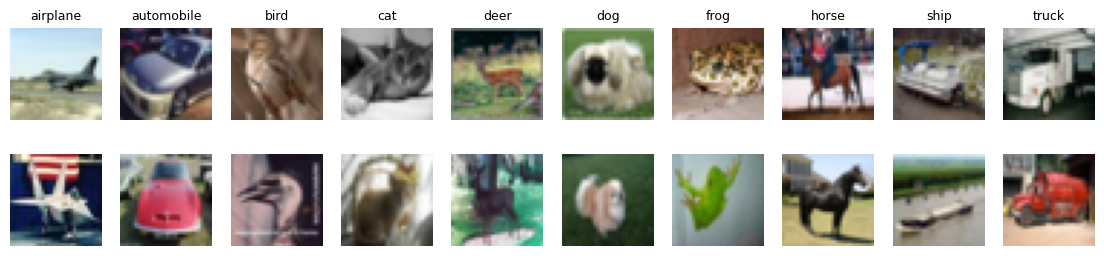

In [3]:
# [Colab] Carga de datos y modelo
import torch, torchvision
from torchvision import datasets, models

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Dispositivo:', device)

train = datasets.CIFAR10('data', train=True, download=True)
test = datasets.CIFAR10('data', train=False, download=True)
clases = train.classes

rng = np.random.default_rng(0)
idx_tr = rng.choice(len(train), 2000, replace=False)
idx_te = rng.choice(len(test), 1000, replace=False)
img_tr = [train[i][0] for i in idx_tr]; y_tr = np.array([train[i][1] for i in idx_tr])
img_te = [test[i][0] for i in idx_te];  y_te = np.array([test[i][1] for i in idx_te])

fig, axes = plt.subplots(2, 10, figsize=(14, 3))
for c in range(10):
    for r in range(2):
        i = np.where(y_tr == c)[0][r]
        axes[r, c].imshow(img_tr[i]); axes[r, c].axis('off')
    axes[0, c].set_title(clases[c], fontsize=9)
plt.show()

## 3. Tres representaciones, un mismo clasificador

Usamos siempre k-NN (k=5) para que la comparación dependa sólo de las **características**:

| Representación | Dimensión | Origen |
|---|---|---|
| Píxeles crudos | 3 072 | 32 × 32 × 3 |
| HOG | 324 | diseñada a mano (notebook anterior) |
| Embedding ResNet-18 | 512 | aprendida en ImageNet, **sin reentrenar** |

In [4]:
# [Colab] Píxeles y HOG
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

def pixeles(ims):
    return np.array([np.asarray(im, dtype=np.float32).ravel() / 255 for im in ims])

def hog(ims):
    return np.array([feature.hog(color.rgb2gray(np.asarray(im)), orientations=9,
                                 pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for im in ims])

def knn_acc(Ftr, Fte, metric='euclidean'):
    clf = KNeighborsClassifier(5, metric=metric).fit(Ftr, y_tr)
    return accuracy_score(y_te, clf.predict(Fte))

resultados = {}
resultados['píxeles (3072)'] = knn_acc(pixeles(img_tr), pixeles(img_te))
H_tr, H_te = hog(img_tr), hog(img_te)
resultados[f'HOG ({H_tr.shape[1]})'] = knn_acc(H_tr, H_te)
print(resultados)

{'píxeles (3072)': 0.274, 'HOG (324)': 0.353}


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 228MB/s]


Embeddings: (2000, 512)


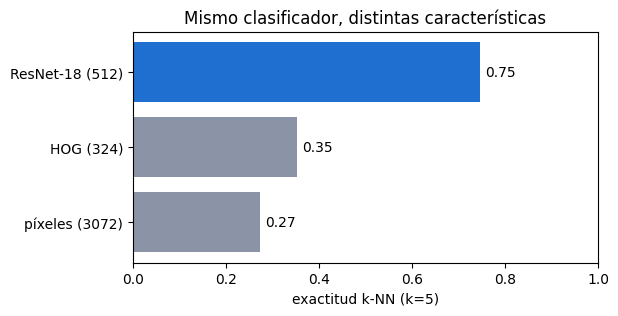

In [5]:
# [Colab] ResNet-18 preentrenada como extractor de características
w = models.ResNet18_Weights.DEFAULT
net = models.resnet18(weights=w)
net.fc = torch.nn.Identity()          # quitamos la capa de clasificación de ImageNet
net = net.eval().to(device)
prep = w.transforms()                 # redimensiona a 224, normaliza como en ImageNet

@torch.no_grad()
def embed(ims, bs=128):
    out = []
    for i in range(0, len(ims), bs):
        x = torch.stack([prep(im) for im in ims[i:i + bs]]).to(device)
        out.append(net(x).cpu())
    return torch.nn.functional.normalize(torch.cat(out), dim=1).numpy()   # normalización L2

E_tr, E_te = embed(img_tr), embed(img_te)
print('Embeddings:', E_tr.shape)
resultados['ResNet-18 (512)'] = knn_acc(E_tr, E_te, metric='cosine')

plt.figure(figsize=(6, 3))
plt.barh(list(resultados.keys()), list(resultados.values()), color=['#8A94A6', '#8A94A6', '#1F6FD1'])
for i, v in enumerate(resultados.values()):
    plt.text(v + 0.01, i, f'{v:.2f}', va='center')
plt.xlim(0, 1); plt.xlabel('exactitud k-NN (k=5)'); plt.title('Mismo clasificador, distintas características')
plt.show()

**Pregunta para pensar:** la ResNet nunca vio CIFAR-10 y no la hemos reentrenado. ¿Por qué sus embeddings funcionan mucho mejor que los píxeles? Pista: dos imágenes de "perro" pueden tener píxeles muy distintos, pero comparten partes (orejas, hocico) que la red aprendió a detectar en ImageNet.

### 3.1 ¿Qué ve la red por dentro?

Con un *hook* capturamos los mapas de características de una capa intermedia.

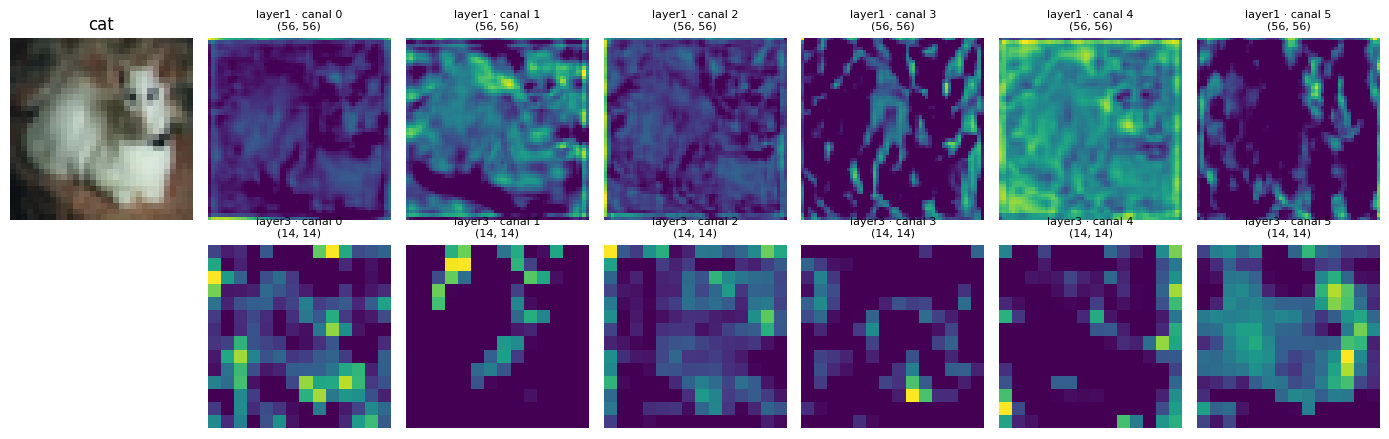

In [6]:
# [Colab] Mapas de características de capas intermedias
mapas = {}
def guardar(nombre):
    def hook(mod, inp, out):
        mapas[nombre] = out.detach().cpu()
    return hook

h1 = net.layer1.register_forward_hook(guardar('layer1'))
h3 = net.layer3.register_forward_hook(guardar('layer3'))
im = img_te[0]
with torch.no_grad():
    net(prep(im).unsqueeze(0).to(device))
h1.remove(); h3.remove()

fig, axes = plt.subplots(2, 7, figsize=(14, 4.4))
axes[0, 0].imshow(im); axes[0, 0].set_title(clases[y_te[0]]); axes[1, 0].axis('off')
for r, capa in enumerate(['layer1', 'layer3']):
    for c in range(1, 7):
        axes[r, c].imshow(mapas[capa][0, c - 1], cmap='viridis')
        axes[r, c].set_title(f'{capa} · canal {c - 1}\n{tuple(mapas[capa].shape[2:])}', fontsize=8)
for a in axes.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

## 4. Visualizar el espacio de embeddings

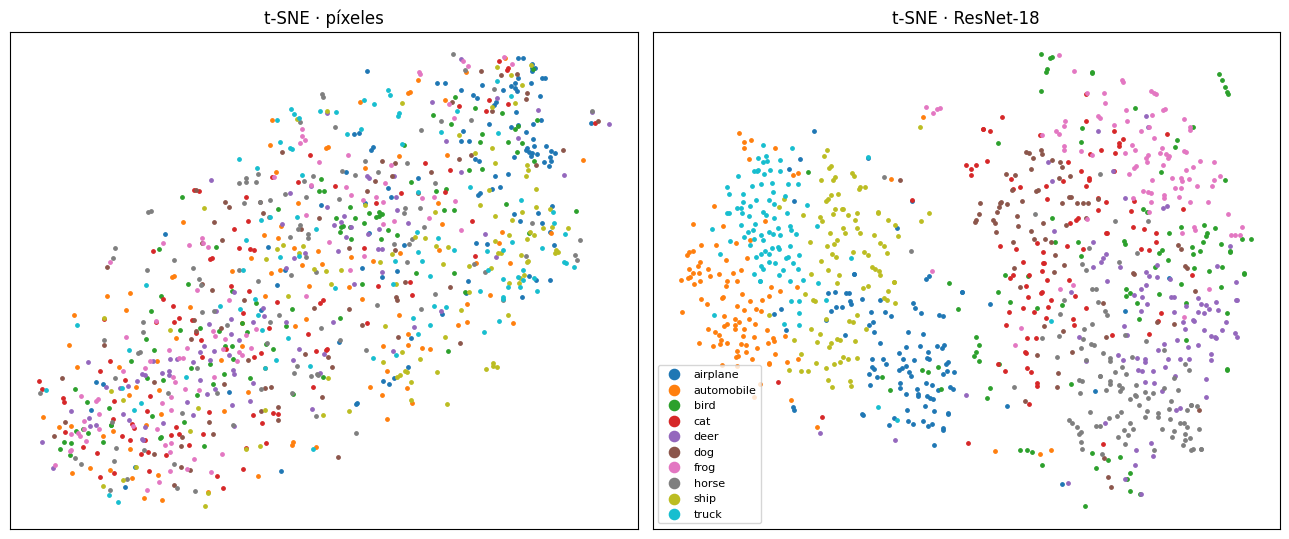

In [7]:
# [Colab] t-SNE de los embeddings frente a los píxeles
from sklearn.manifold import TSNE

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for ax, (nombre, F) in zip(axes, [('píxeles', pixeles(img_te)), ('ResNet-18', E_te)]):
    Z = TSNE(2, random_state=0, init='pca', perplexity=30).fit_transform(F)
    for c in range(10):
        m = y_te == c
        ax.scatter(Z[m, 0], Z[m, 1], s=6, label=clases[c])
    ax.set_title(f't-SNE · {nombre}'); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=3, fontsize=8, loc='best')
plt.tight_layout(); plt.show()

## 5. CLIP: imágenes y texto en el mismo espacio

CLIP tiene dos codificadores (imagen y texto) entrenados para que una imagen y su descripción tengan embeddings parecidos. Usamos el modelo público `openai/clip-vit-base-patch32` a través de la librería `transformers`, que ya está instalada en Colab.

In [8]:
# [Colab] Cargar CLIP
from transformers import CLIPModel, CLIPProcessor

clip = CLIPModel.from_pretrained('openai/clip-vit-base-patch32').to(device).eval()
proc = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch32')

def _tensor(o, claves=('image_embeds', 'text_embeds', 'pooler_output')):
    """Según la versión de transformers, get_*_features devuelve un tensor o un objeto."""
    if torch.is_tensor(o):
        return o
    for k in claves:
        if getattr(o, k, None) is not None:
            return getattr(o, k)
    return o[0]

@torch.no_grad()
def clip_imagenes(ims, bs=64):
    out = []
    for i in range(0, len(ims), bs):
        inp = proc(images=ims[i:i + bs], return_tensors='pt').to(device)
        out.append(_tensor(clip.get_image_features(**inp)).cpu())
    return torch.nn.functional.normalize(torch.cat(out), dim=1)

@torch.no_grad()
def clip_textos(textos):
    inp = proc(text=textos, return_tensors='pt', padding=True).to(device)
    return torch.nn.functional.normalize(_tensor(clip.get_text_features(**inp)).cpu(), dim=1)

C_te = clip_imagenes(img_te)
print('Embeddings de imagen CLIP:', tuple(C_te.shape))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

...

vocab.json:   0%|          | 0.00/862k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

Embeddings de imagen CLIP: (1000, 512)


### 5.1 Búsqueda por texto

Codificamos una frase y ordenamos las imágenes por similitud coseno con ella. Nunca le hemos dicho a CLIP qué hay en estas imágenes.

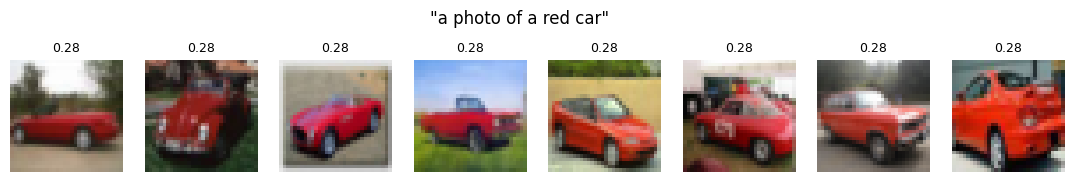

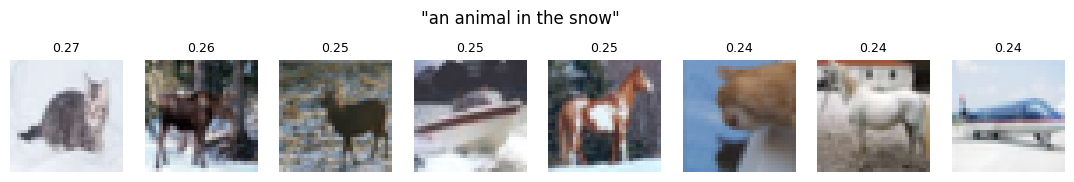

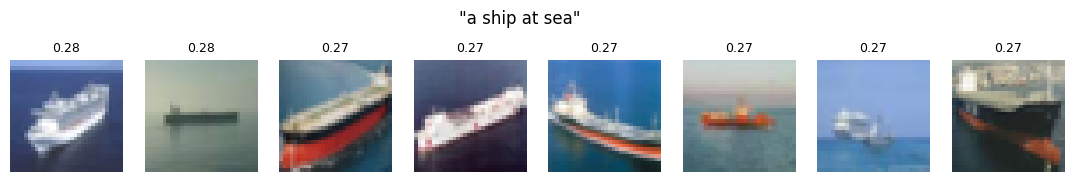

In [11]:
# [Colab] Buscar imágenes con una frase
def buscar(frase, k=8):
    t = clip_textos([frase])
    sims = (C_te @ t.T).squeeze(1)
    top = sims.argsort(descending=True)[:k].tolist()
    fig, axes = plt.subplots(1, k, figsize=(1.7 * k, 2.2))
    for ax, i in zip(axes, top):
        ax.imshow(img_te[i]); ax.axis('off'); ax.set_title(f'{sims[i]:.2f}', fontsize=9)
    plt.suptitle(f'"{frase}"'); plt.show()

buscar('a photo of a red car')
buscar('an animal in the snow')
buscar('a ship at sea')

### 5.2 Clasificación *zero-shot*

Escribimos una frase por clase y asignamos a cada imagen la clase cuya frase es más parecida. Probamos una plantilla y la media de varias (*prompt ensembling*).

In [12]:
# [Colab] Zero-shot con una plantilla y con varias
plantillas = ['a photo of a {}.', 'a blurry photo of a {}.', 'a low resolution photo of a {}.', 'a close-up photo of a {}.']

def zero_shot(plantillas):
    T = torch.stack([clip_textos([p.format(c) for c in clases]) for p in plantillas]).mean(0)
    T = torch.nn.functional.normalize(T, dim=1)
    return (C_te @ T.T).argmax(1).numpy()

pred1 = zero_shot(plantillas[:1])
pred4 = zero_shot(plantillas)
print(f'Zero-shot, 1 plantilla : {accuracy_score(y_te, pred1):.3f}')
print(f'Zero-shot, 4 plantillas: {accuracy_score(y_te, pred4):.3f}')
print(f'k-NN sobre embeddings CLIP (con 2000 etiquetas): '
      f'{accuracy_score(y_te, KNeighborsClassifier(5, metric="cosine").fit(clip_imagenes(img_tr).numpy(), y_tr).predict(C_te.numpy())):.3f}')

Zero-shot, 1 plantilla : 0.882
Zero-shot, 4 plantillas: 0.891
k-NN sobre embeddings CLIP (con 2000 etiquetas): 0.902


## 6. Ejercicios

1. Cambia ResNet-18 por ResNet-50 (`models.resnet50`, embedding de 2048). ¿Mejora la exactitud? ¿Cuánto más tarda?
2. Entrena una regresión logística en lugar de k-NN sobre los embeddings de ResNet. ¿Cuántas imágenes de entrenamiento necesitas para superar el 80 %?
3. Busca con CLIP frases que **no** sean clases de CIFAR-10 («something you can ride», «a cute animal»). ¿Tienen sentido los resultados?
4. Encuentra 5 imágenes que CLIP clasifique mal en *zero-shot* y explica qué tienen en común. Relaciónalo con la **brecha semántica**.